In [1]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
path = r'../../data/limpieza/cleaned_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,volatilidad_200_dxy,momentum_50_dxy,momentum_200_dxy,var_diaria_dxy,rango_dia_dxy,RSI_dxy,pct_cambio_7d,tendencia_futura_7d,pct_cambio_30d,tendencia_futura_30d
0,2023-03-01,23141.57,24000.00,23020.03,23628.97,315287.41737,9390487.0,7.449917e+09,22679.9494,19737.60555,...,3.608698,1.240005,-1.456662,-0.371888,1.000000,61.023720,-4.381577,-1,7.835372,1
1,2023-03-02,23629.76,23796.93,23195.90,23465.32,239315.45219,7435815.0,5.615614e+09,22790.3906,19733.40595,...,3.611084,1.839996,-1.213336,0.526412,0.790001,69.306908,-6.000538,-1,8.496134,1
2,2023-03-03,23465.32,23476.95,21971.13,22354.34,319954.19785,8214639.0,7.152365e+09,22860.5450,19724.70355,...,3.615337,2.269997,-2.030006,-0.485578,0.510002,59.321975,-6.874378,-1,9.543986,1
3,2023-03-04,22354.34,22410.00,22157.08,22346.57,121257.38132,4169260.0,2.709687e+09,22908.8762,19717.16270,...,3.619720,2.263334,-2.036669,-0.054216,0.516668,57.440711,-7.575719,-1,10.506276,1
4,2023-03-05,22346.57,22662.09,22189.22,22430.24,154841.75786,4835978.0,3.473138e+09,22938.3826,19712.60060,...,3.624319,2.159167,-2.163335,-0.054245,0.523333,55.534314,-7.198816,-1,11.489685,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
737,2025-03-07,89931.88,91283.02,84667.03,86801.75,57980.35713,9510442.0,5.032796e+09,96830.4536,83041.65370,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-7.069163,-1,-10.060273,-1
738,2025-03-08,86801.74,86897.25,85218.47,86222.45,12989.23054,2553974.0,1.119963e+09,96473.3530,83177.69695,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-7.396003,-1,-9.980073,-1
739,2025-03-09,86222.46,86500.00,80000.00,80734.37,26115.39345,5189138.0,2.108410e+09,95996.9158,83275.58865,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-5.030962,-1,-9.626627,-1
740,2025-03-10,80734.48,84123.46,77459.91,78595.86,47633.38405,8701538.0,3.743787e+09,95542.2016,83366.68875,...,2.870296,-1.559998,2.010002,-0.689589,0.610001,30.088413,-2.922354,-1,-9.068330,-1


# Visualización de la variable respuesta (7 días)

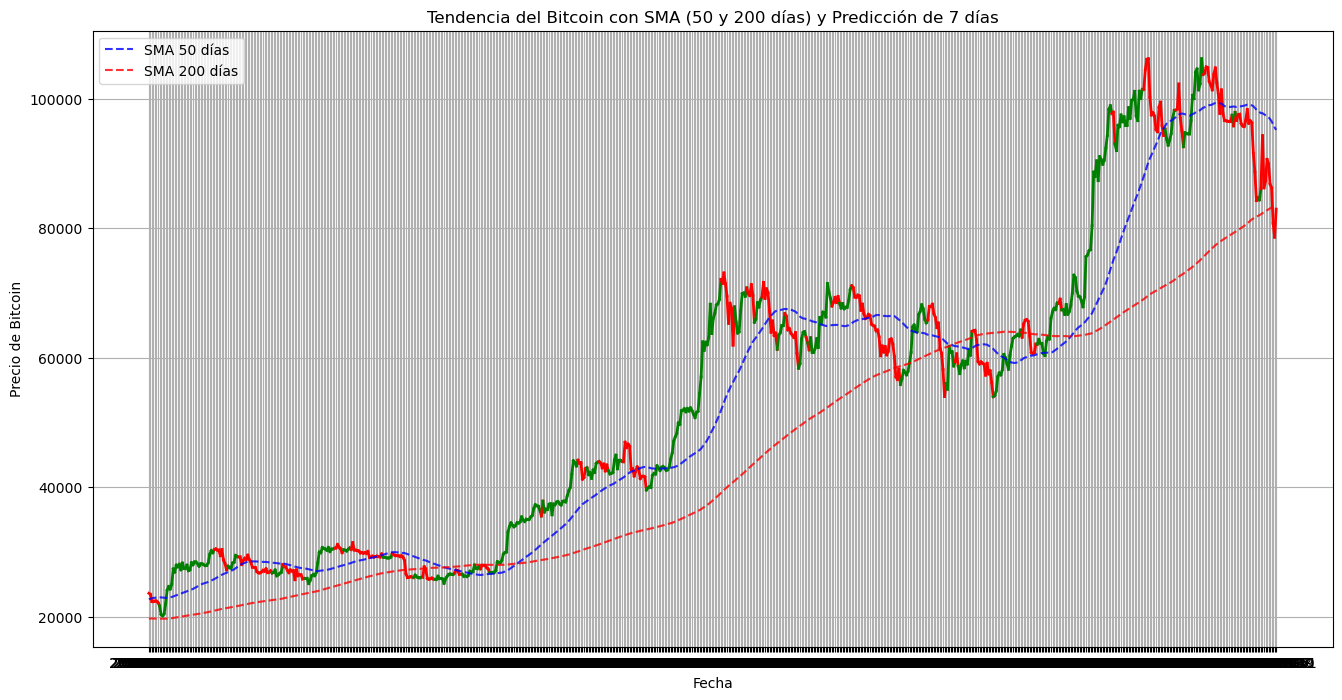

In [3]:
# Crear una visualización donde la línea de "close_binance" cambie de color según la tendencia futura
# Agregando un color adicional para la tendencia neutral

df_plot = df
# Configurar la figura
plt.figure(figsize=(16, 8))

# Recorrer el dataset para cambiar el color del precio de cierre según la tendencia
for i in range(1, len(df_plot)):
    if df_plot.iloc[i]['tendencia_futura_7d'] == 1:
        color = 'green'  # Alcista
    elif df_plot.iloc[i]['tendencia_futura_7d'] == -1:
        color = 'red'  # Bajista
    else:
        color = 'gray'  # Neutral

    plt.plot(df_plot['timestamp'].iloc[i-1:i+1], df_plot['close_binance'].iloc[i-1:i+1], color=color, linewidth=2)

# Graficar las medias móviles
plt.plot(df_plot['timestamp'], df_plot['SMA_50_binance'], label="SMA 50 días", linestyle="dashed", color="blue", alpha=0.8)
plt.plot(df_plot['timestamp'], df_plot['SMA_200_binance'], label="SMA 200 días", linestyle="dashed", color="red", alpha=0.8)

# Configuración de la gráfica
plt.xlabel("Fecha")
plt.ylabel("Precio de Bitcoin")
plt.title("Tendencia del Bitcoin con SMA (50 y 200 días) y Predicción de 7 días")
plt.legend()
plt.grid()

# Mostrar la gráfica mejorada con colores en la línea de precio
plt.show()

# Correlacion con variable respuesta

In [4]:
corr_matrix = df[['open_binance', 'high_binance', 'low_binance', 'close_binance', 'volume_binance', 'trades_binance',
                 'Close_sp500', 'High_sp500', 'Low_sp500', 'Open_sp500', 'Volume_sp500',
                 'Close_nasdaq', 'High_nasdaq', 'Low_nasdaq', 'Open_nasdaq', 'Volume_nasdaq',
                 'Close_dxy', 'High_dxy', 'Low_dxy', 'Open_dxy', 'pct_cambio_7d', 'pct_cambio_30d']].dropna().corr(method='pearson')

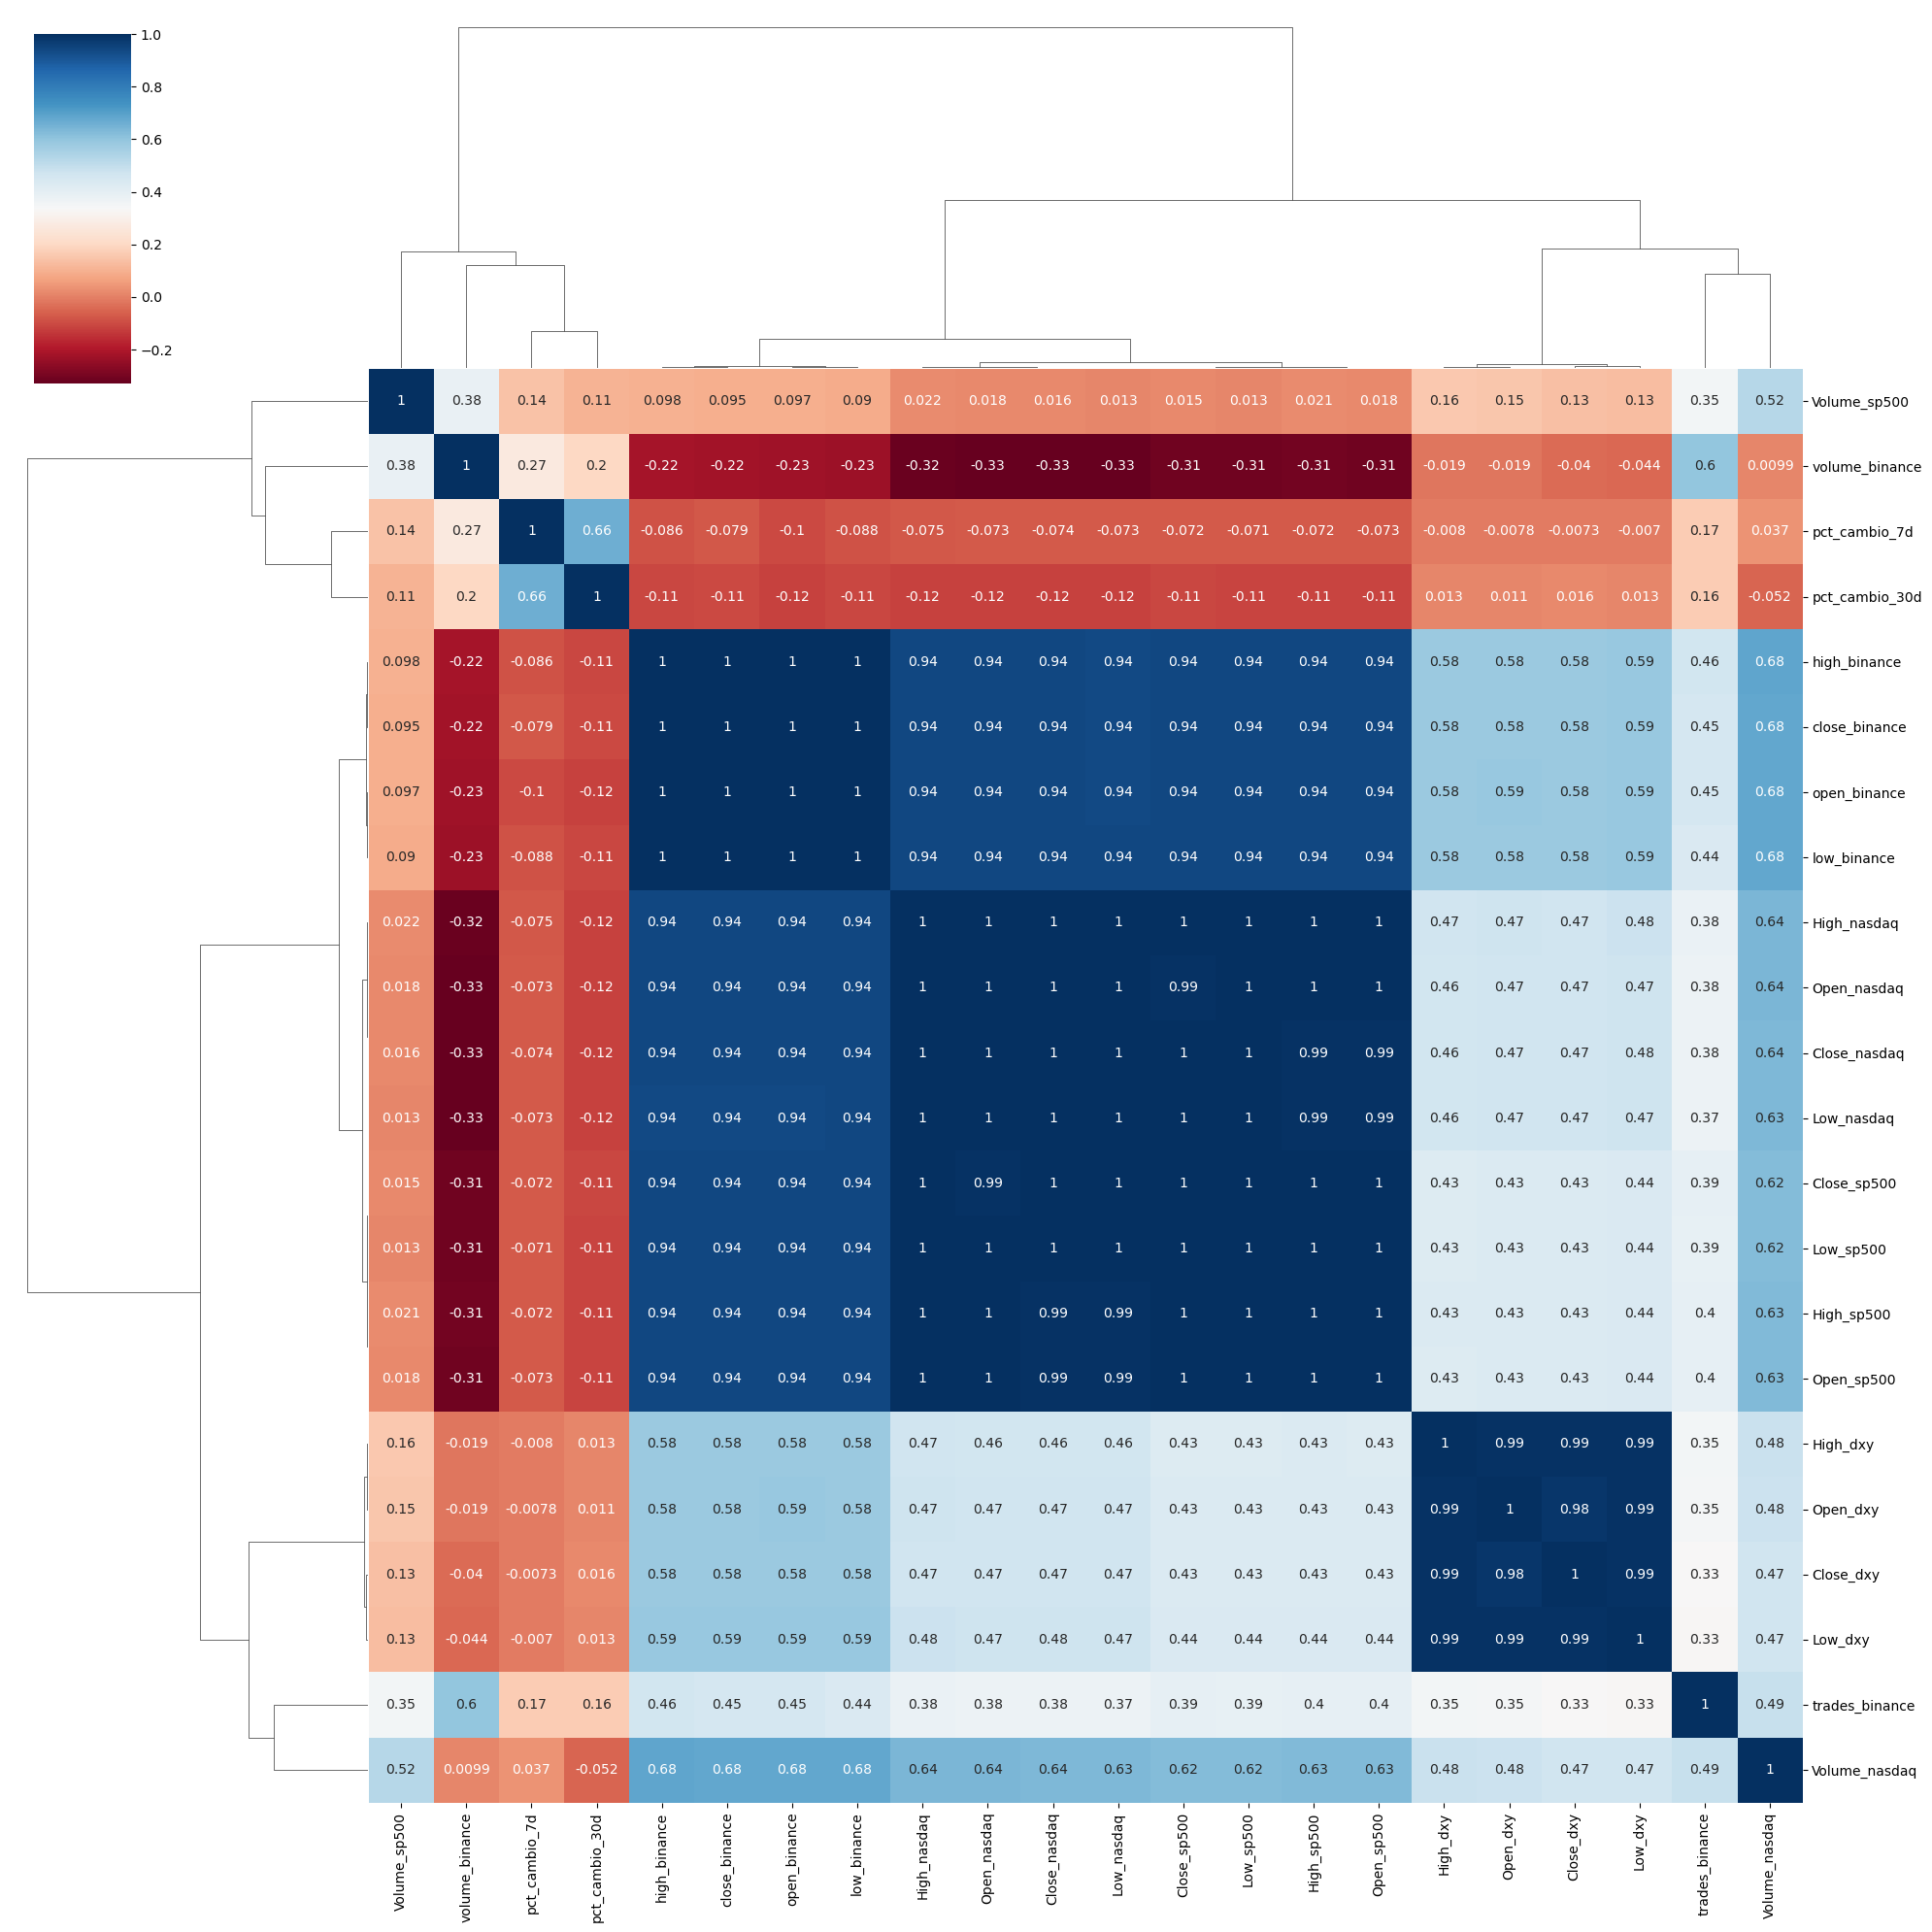

In [5]:
# Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 10}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()